# 04 Results: final test evaluation and impact

- What it does: refits every model on train + validation with the frozen settings, scores the test years (2024 onward), and translates the results into impact for ISD.
- Inputs: `data/processed/model_table.parquet`, `data/processed/inspections_full.parquet`, `docs/FROZEN_CONFIG.json`.
- Outputs: `preds/*_test.csv`, `results/results.csv`, `results/model_differences.csv`, `results/results_by_year.csv`, `results/rule_sensitivity.csv`, `results/robustness.csv`, `results/capacity_sensitivity.csv`, `results/calibration.csv`, `results/neighborhood_table.csv`, `results/after_a_pass.csv`, `results/impact.csv`, `results/feature_importance.csv`, `results/permutation_importance.csv`, `results/priority_list.csv`, and the figures `gains_curve_test.png`, `hit_rate_bar.png`, `text_value_bar.png`, `feature_importance.png`, `impact_bar.png`, `serious_violations_bar.png`, `neighborhood_first_visits.png` in `results/figures/`.

No setting is tuned here. Every setting comes from `docs/FROZEN_CONFIG.json`, which was committed before the test years were scored.

In [1]:
import sys
sys.path.insert(0, "..")

import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

from src import evaluate as E
from src import features as F
from src import impact as I
from src import models as M
from src import text as T

SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

FROZEN = json.load(open("../docs/FROZEN_CONFIG.json"))
FINAL = FROZEN["final_model"]          # the model we would deploy, chosen on validation
assert FROZEN["history_features"] == M.HISTORY_FEATURES, "feature list changed after the freeze"
print("final model (chosen on validation):", FINAL)
print("M1 settings:", FROZEN["M1_lgbm"])
print("M2 settings:", FROZEN["M2_lgbm_text"])

final model (chosen on validation): M1_lgbm
M1 settings: {'features': 'history', 'num_leaves': 31, 'learning_rate': 0.02, 'n_estimators': 231}
M2 settings: {'features': 'history + 32 text PCs + has_prior_comments', 'num_leaves': 7, 'learning_rate': 0.05, 'n_estimators': 100, 'encoder': 'sentence-transformers/all-MiniLM-L6-v2', 'encoder_revision': '1110a243fdf4706b3f48f1d95db1a4f5529b4d41', 'max_tokens': 256, 'pooling': 'mean over attention mask', 'pca_components': 32, 'note': 'embeddings differ in the 6th decimal between devices, which can move M2 by about 0.3 points'}


## 1. Refit on train + validation, score the test years

With the settings frozen, the validation year has done its job, so it joins the training data. LightGBM uses the number of trees that early stopping found on validation.

In [2]:
table = M.load_model_table("../data/processed/model_table.parquet")
is_fit = table["split"].isin(["train", "val"]).to_numpy()
is_test = (table["split"] == "test").to_numpy()
has_text = (table["prior_comments"].str.strip() != "").to_numpy()

# Text features for M2. The PCA is refitted on train + validation rows only.
embeddings = T.embed_cached(table["inspection_id"], table["prior_comments"], cache_dir="../data/processed")
pca = T.fit_pca(embeddings, fit_mask=is_fit & has_text)
table = T.add_text_features(table, embeddings, pca)
FEATURES_M2 = M.HISTORY_FEATURES + T.TEXT_FEATURES

fit, test = table[is_fit], table[is_test]
# Nothing is ever fitted on the test period: not the models, not the PCA, not B1's fallback.
assert fit["date"].max() < pd.Timestamp("2024-01-01") <= test["date"].min()
assert table.loc[is_fit & has_text, "date"].max() < pd.Timestamp("2024-01-01")     # rows the PCA was fitted on
y_test = test[M.TARGET].to_numpy()
print(f"fit on {len(fit):,} inspections (2016 to 2023) | test on {len(test):,} inspections "
      f"({test['date'].min().date()} to {test['date'].max().date()}), fail rate {y_test.mean():.1%}")

Loaded cached embeddings: ../data/processed/embeddings.npy
fit on 41,393 inspections (2016 to 2023) | test on 17,171 inspections (2024-01-02 to 2026-11-10), fail rate 59.0%


In [3]:
lgbm_keys = ["num_leaves", "learning_rate", "n_estimators"]
params_m1 = {k: FROZEN["M1_lgbm"][k] for k in lgbm_keys}
params_m2 = {k: FROZEN["M2_lgbm_text"][k] for k in lgbm_keys}

logreg = M.fit_logreg(fit)
m1 = M.fit_lgbm(fit, M.HISTORY_FEATURES, params_m1)
m2 = M.fit_lgbm(fit, FEATURES_M2, params_m2)

test_scores = {
    "B0_random": M.score_random(test),
    "B1_past_fail_rate": M.score_past_fail_rate(test, fallback=M.past_fail_rate_fallback(fit)),
    "B2_logreg": logreg.predict_proba(M.linear_matrix(test))[:, 1],
    "M1_lgbm": m1.predict_proba(test[M.HISTORY_FEATURES])[:, 1],
    "M2_lgbm_text": m2.predict_proba(test[FEATURES_M2])[:, 1],
}
for name, score in test_scores.items():
    M.save_preds(test, score, f"../preds/{name}_test.csv")

## 2. Test results

Capacity is 20% of inspections. The hit rate (`precision_at_k`) is the share of those visits that find a failure. Intervals are 95% bootstrap intervals (500 resamples of whole restaurants). B0 is the average over every random order, so its hit rate equals the fail rate.

In [4]:
test_groups = test["licenseno"].to_numpy()      # confidence intervals resample whole restaurants
results = E.results_table(y_test, test_scores, groups=test_groups)
results.to_csv("../results/results.csv", index=False)
results.round(3)

,model,auc,catch_at_k,precision_at_k,n,auc_lo,auc_hi,catch_at_k_lo,catch_at_k_hi,precision_at_k_lo,precision_at_k_hi
0,B0_random,0.500,0.200,0.590,17171,0.500,0.500,0.200,0.200,0.578,0.599
1,B1_past_fail_rate,0.698,0.272,0.803,17171,0.688,0.708,0.267,0.278,0.785,0.817
2,B2_logreg,0.736,0.295,0.870,17171,0.727,0.746,0.290,0.300,0.852,0.882
3,M1_lgbm,0.748,0.299,0.881,17171,0.738,0.757,0.293,0.304,0.864,0.894
4,M2_lgbm_text,0.747,0.301,0.888,17171,0.738,0.756,0.296,0.307,0.874,0.902


Is the final model better than each alternative? Each row is "final model minus the other model" on the same 10,000 bootstrap resamples of whole restaurants. The verdict has three levels, defined in the frozen config before the test years were scored: "beyond noise", "borderline" (the interval's end nearest zero is about zero) and "within noise".

In [5]:
differences = E.difference_table(y_test, test_scores, FINAL, [m for m in test_scores if m != FINAL], groups=test_groups)
differences.to_csv("../results/model_differences.csv", index=False)
hit_diffs = differences[differences["metric"] == "precision_at_k"]
print(hit_diffs.round(4).to_string(index=False))

print()
for row in hit_diffs.itertuples():
    print(f"{E.MODEL_LABELS[FINAL]} vs. {E.MODEL_LABELS[row.minus]}: {row.difference * 100:+.1f} points of hit rate "
          f"(95% CI {row.ci_lo * 100:+.1f} to {row.ci_hi * 100:+.1f}): {row.verdict}.")

  model             minus         metric  difference   ci_lo   ci_hi      verdict
M1_lgbm         B0_random precision_at_k      0.2909  0.2775  0.3032 beyond noise
M1_lgbm B1_past_fail_rate precision_at_k      0.0784  0.0655  0.0909 beyond noise
M1_lgbm         B2_logreg precision_at_k      0.0108  0.0032  0.0193 beyond noise
M1_lgbm      M2_lgbm_text precision_at_k     -0.0067 -0.0144 -0.0015 beyond noise

LightGBM, history vs. Random order (assumed status quo): +29.1 points of hit rate (95% CI +27.8 to +30.3): beyond noise.
LightGBM, history vs. Past failure rate (simple rule): +7.8 points of hit rate (95% CI +6.5 to +9.1): beyond noise.
LightGBM, history vs. Logistic regression: +1.1 points of hit rate (95% CI +0.3 to +1.9): beyond noise.
LightGBM, history vs. LightGBM, history + text: -0.7 points of hit rate (95% CI -1.4 to -0.1): beyond noise.


### Reading the test results

- Against the assumed random order and against the past-failure-rate rule, the final model's lead is large and beyond noise.
- Against logistic regression, the lead is about one point of hit rate. It is beyond noise on the test years and was borderline on validation. Most of the gain comes from the history features, which both models share, and little from the choice of algorithm.
- The text model (M2) is 0.7 points ahead of the final model on the test years. The 95% interval of the difference excludes zero with every bootstrap seed we tried. Under our stricter frozen rule the verdict sits on the line between "beyond noise" and "borderline". The edge is about twice M2's device noise (0.3 points). Validation showed no such edge. M2 leads in each of the three test years. We keep M1 because the choice was fixed on validation, and switching after seeing the test years would be tuning on the test. A fair summary: the previous inspection's comments add somewhere between zero and one and a half points.

The verdict printed for each row follows the definition frozen before the test was scored.

### By year

The headline numbers rank all test inspections together. Here each test year is ranked on its own (top 20% of that year), to check that the result does not come from one year. 2026 stops on November 10.

In [6]:
by_year = []
for year, idx in test.groupby("year").indices.items():
    for name, score in test_scores.items():
        by_year.append({"year": year, "model": name, "n": len(idx), "fail_rate": y_test[idx].mean(),
                        "precision_at_k": E.evaluate(y_test[idx], score[idx])["precision_at_k"]})
by_year = pd.DataFrame(by_year)
# Yearly gain of the final model, in failed inspections found in the first 20% of that year's visits
# (2026 is scaled up to a full year).
days = test.groupby("year")["date"].agg(lambda d: (d.max() - d.min()).days + 1)
by_year["visits_per_year"] = E.K * by_year["n"] * 365.25 / by_year["year"].map(days)
by_year["extra_vs_random_per_year"] = (by_year["precision_at_k"] - by_year["fail_rate"]) * by_year["visits_per_year"]
# The same gain measured against the visits ISD actually made first in each quarter of that year.
actual, ranked = {}, {}
for year, idx in test.groupby("year").indices.items():
    actual[year] = I.first_visits_hit_rate(test["date"].iloc[idx], y_test[idx], None)
    ranked[year] = {name: I.first_visits_hit_rate(test["date"].iloc[idx], y_test[idx], score[idx]) for name, score in test_scores.items()}
by_year["extra_vs_actual_order_per_year"] = [
    (ranked[r.year][r.model] - actual[r.year]) * r.visits_per_year for r in by_year.itertuples()]
by_year.to_csv("../results/results_by_year.csv", index=False)
print(by_year.pivot(index="model", columns="year", values="precision_at_k").loc[list(test_scores)].round(3).to_string())
final_by_year = by_year[by_year["model"] == FINAL].set_index("year")
print(f"\n{E.MODEL_LABELS[FINAL]}: extra failed inspections found in the first 20%, per year")
print("  vs. random order:      ", {int(y): int(round(v)) for y, v in final_by_year["extra_vs_random_per_year"].items()})
print("  vs. ISD's actual order:", {int(y): int(round(v)) for y, v in final_by_year["extra_vs_actual_order_per_year"].items()})

year                2024   2025   2026
model                                 
B0_random          0.595  0.562  0.618
B1_past_fail_rate  0.821  0.809  0.768
B2_logreg          0.895  0.880  0.837
M1_lgbm            0.901  0.889  0.849
M2_lgbm_text       0.910  0.896  0.858

LightGBM, history: extra failed inspections found in the first 20%, per year
  vs. random order:       {2024: 346, 2025: 407, 2026: 288}
  vs. ISD's actual order: {2024: 334, 2025: 393, 2026: 234}


The gain moves from year to year by more than the bootstrap interval suggests, and 2026 is the weakest year for every method. The interval only reflects which restaurants happen to be in the sample. It does not cover change from one year to the next.

### Other capacities, and calibration

20% is an illustrative capacity. The table shows the hit rate if ISD could only prioritize 5% of its visits, or as many as 50%. "Best possible" is what a perfect ranking would reach.

The second table checks the risk percentages themselves: among inspections the final model scores around 80%, do about 80% fail?

In [7]:
capacity = I.capacity_table(y_test, test_scores)
capacity.to_csv("../results/capacity_sensitivity.csv", index=False)
print(capacity.round(3).to_string(index=False))

calibration = I.calibration_table(y_test, test_scores[FINAL])
calibration.to_csv("../results/calibration.csv", index=False)
print()
print(calibration.round(3).to_string(index=False))

 capacity  random_order  best_possible  B1_past_fail_rate  B2_logreg  M1_lgbm  M2_lgbm_text
     0.05          0.59            1.0              0.732      0.921    0.937         0.935
     0.10          0.59            1.0              0.778      0.906    0.927         0.927
     0.20          0.59            1.0              0.803      0.870    0.881         0.888
     0.30          0.59            1.0              0.785      0.829    0.838         0.844
     0.50          0.59            1.0              0.744      0.757    0.765         0.764

 group    n  mean_predicted_risk  observed_fail_rate
     1 1718                0.199               0.234
     2 1717                0.297               0.330
     3 1717                0.372               0.465
     4 1717                0.450               0.484
     5 1717                0.525               0.566
     6 1717                0.606               0.624
     7 1717                0.693               0.683
     8 1717            

### Sensitivity: a second simple rule

The gain over "the rule" depends on the rule. B1 ranks by past failure rate, the rule we planned to benchmark against from the start. An inspector could also rank by the number of violations at the last routine inspection. This row is not one of the five models. It shows how much of the model's performance one well-chosen number already delivers.

In [8]:
simple_rule = M.score_simple_rule(test)
sensitivity = E.results_table(y_test, {"S1_last_routine_violations": simple_rule}, groups=test_groups)
d, lo, hi = E.paired_differences(y_test, test_scores[FINAL], simple_rule, groups=test_groups)["precision_at_k"]
sensitivity["final_model_minus_rule"], sensitivity["diff_ci_lo"], sensitivity["diff_ci_hi"] = d, lo, hi
sensitivity.to_csv("../results/rule_sensitivity.csv", index=False)
print(f"'Most violations at the last routine inspection first': hit rate {sensitivity['precision_at_k'][0]:.1%}")
print(f"{E.MODEL_LABELS[FINAL]} minus this rule: {d * 100:+.1f} points (95% CI {lo * 100:+.1f} to {hi * 100:+.1f})")

'Most violations at the last routine inspection first': hit rate 81.9%
LightGBM, history minus this rule: +6.2 points (95% CI +4.9 to +7.4)


### Figures

Made for slides: plain names, one message each. "Random order" stands for today's routine schedule, which is an assumption (see the impact section).

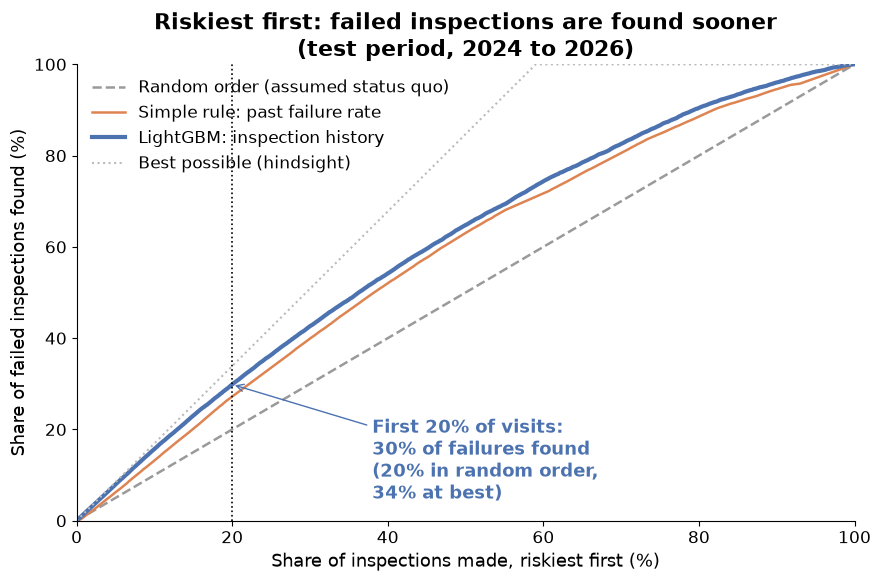

In [9]:
shown = {name: test_scores[name] for name in ["B0_random", "B1_past_fail_rate", FINAL]}
fig = E.plot_gains(y_test, shown, "Riskiest first: failed inspections are found sooner\n(test period, 2024 to 2026)",
                   path="../results/figures/gains_curve_test.png", highlight=FINAL)
plt.show()

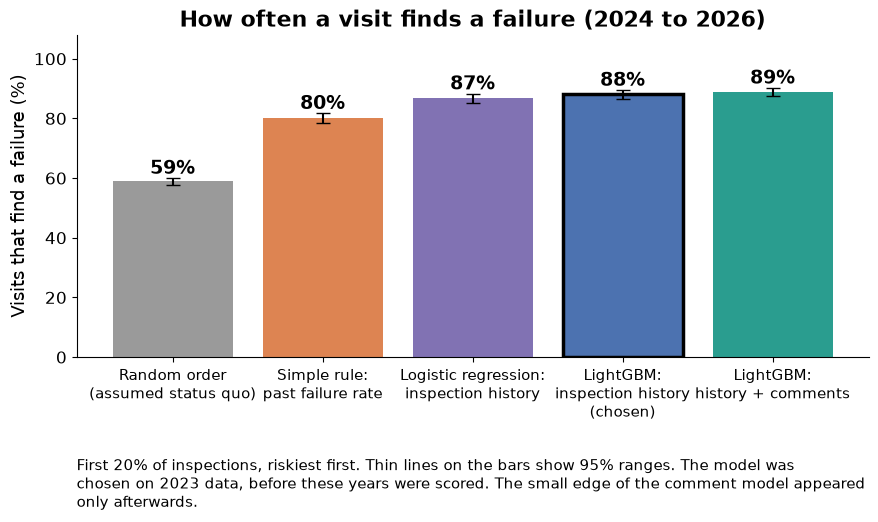

In [10]:
fig = E.plot_hit_rate_bar(results, "How often a visit finds a failure (2024 to 2026)",
                          path="../results/figures/hit_rate_bar.png", final=FINAL,
                          note="The model was chosen on 2023 data, before these years were scored. "
                               "The small edge of the comment model appeared only afterwards.")
plt.show()

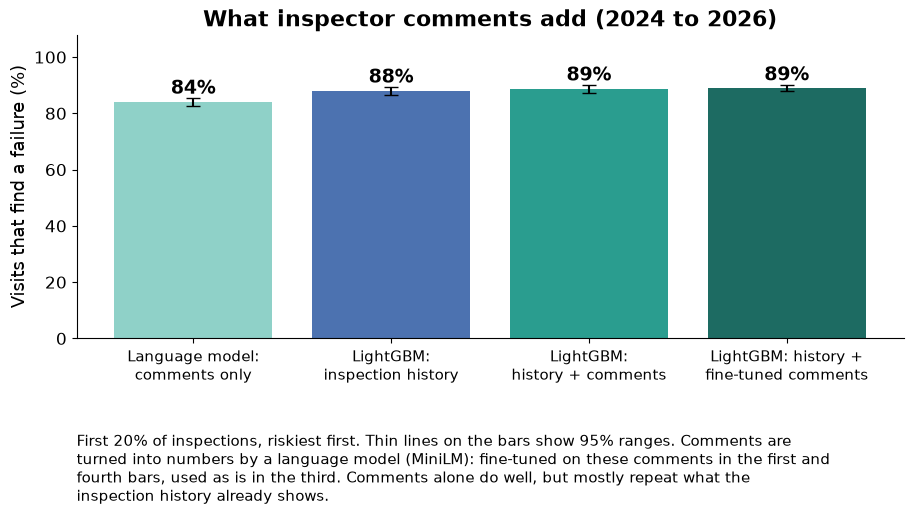

In [11]:
# Text figure. Uses notebook 05's saved test results (fine-tuned encoder), so it is skipped
# until notebook 05 has been run once.
from pathlib import Path
ft_path = Path("../results/finetune_test.csv")
if ft_path.exists():
    ft = pd.read_csv(ft_path).set_index("model")
    ft = ft.loc[["T_finetuned_text_only", "M1_lgbm", "M2_lgbm_text", "M3_lgbm_finetuned"]].reset_index()
    fig = E.plot_hit_rate_bar(ft, "What inspector comments add (2024 to 2026)",
                              path="../results/figures/text_value_bar.png",
                              note="Comments are turned into numbers by a language model (MiniLM): fine-tuned on these comments "
                                   "in the first and fourth bars, used as is in the third. Comments alone do well, but "
                                   "mostly repeat what the inspection history already shows.")
    plt.show()

### What the ranking depends on

LightGBM's own importance measure, split gain, adds up how much each input reduced the training error. It measures how much the model used an input while learning, not what the input adds on new data, and it favors inputs with many distinct values: zip code has 35 and gets 11% of the gain. It is saved in `results/feature_importance.csv` for reference.

The chart uses a shuffle test instead (permutation importance): scramble one input across the test inspections so it carries no information, keep the frozen model, and measure how far the hit rate falls. Each input is scrambled 20 times. Nothing is refitted, so this is reporting on the frozen predictions, not tuning.

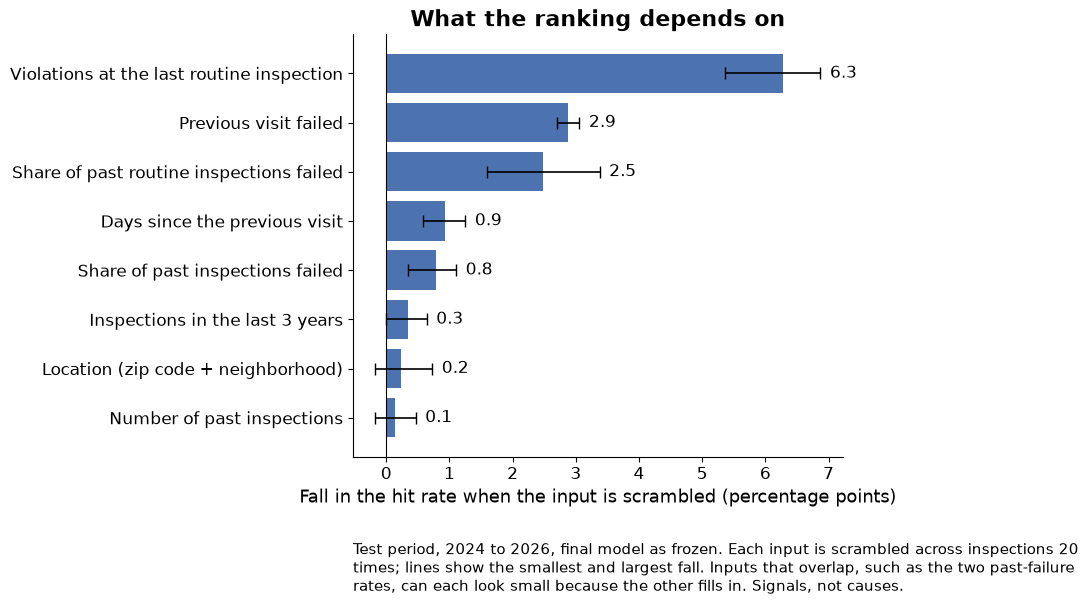

,input,hit_rate_drop_points,drop_min_points,drop_max_points,repeats
0,last_routine_n_viol,6.27,5.36,6.87,20
1,last_fail,2.88,2.71,3.06,20
2,prior_routine_fail_rate,2.48,1.60,3.38,20
3,days_since_last,0.93,0.58,1.25,20
4,prior_fail_rate,0.79,0.35,1.11,20
5,prior_n_3y,0.35,0.00,0.64,20
6,location,0.23,-0.17,0.73,20
7,prior_n,0.13,-0.17,0.47,20
8,license_age_days,0.10,-0.26,0.32,20
9,is_takeout,0.03,-0.03,0.09,20


In [12]:
final_model = {"M1_lgbm": m1, "M2_lgbm_text": m2}[FINAL]
final_features = {"M1_lgbm": M.HISTORY_FEATURES, "M2_lgbm_text": FEATURES_M2}[FINAL]

# Split gain: how much the model used each input while training. Kept for reference; it favors
# inputs with many distinct values, such as zip code (35 values).
importance = M.importance_table(final_model, final_features, top=15)
importance.to_csv("../results/feature_importance.csv", index=False)

# What each input adds to the ranking: scramble it across the test inspections, keep the frozen
# model, and measure how far the hit rate falls. Zip and neighborhood carry the same information,
# so they are scrambled together as "location".
groups = {f: [f] for f in final_features if f not in ("zip", "neighborhood")}
groups["location"] = ["zip", "neighborhood"]
perm = E.permutation_importance(final_model, test, y_test, groups)
perm.to_csv("../results/permutation_importance.csv", index=False)
fig = E.plot_importance(perm, "What the ranking depends on", path="../results/figures/feature_importance.png", top=8,
                        note="Test period, 2024 to 2026, final model as frozen. Each input is scrambled across "
                             "inspections 20 times; lines show the smallest and largest fall. Inputs that overlap, "
                             "such as the two past-failure rates, can each look small because the other fills in. "
                             "Signals, not causes.")
plt.show()
perm.round(2)


### Robustness

Two slices of the same predictions, to see what the headline depends on.

1. Without likely late follow-ups. The 30-day rule removes most re-inspections, but a few follow-ups come later and stay in the data. They usually pass, which hurts the past-failure-rate rule. Here we drop every test inspection whose previous visit failed.
2. One inspection per restaurant. The riskiest 20% of inspections are mostly repeat visits to the same restaurants over three years. Here each restaurant counts once, with its first test inspection.

In [13]:
no_follow_up = (test["last_fail"] != 1).to_numpy()
first_visit = (~test.sort_values("date").duplicated("licenseno")).reindex(test.index).to_numpy()
slices = {"all test inspections": np.ones(len(test), dtype=bool),
          "without likely late follow-ups": no_follow_up,
          "one inspection per restaurant": first_visit}
robust = []
for label, keep in slices.items():
    part = E.results_table(y_test[keep], {name: s[keep] for name, s in test_scores.items()}, groups=test_groups[keep])
    d, lo, hi = E.paired_differences(y_test[keep], test_scores[FINAL][keep], test_scores["B1_past_fail_rate"][keep],
                                     n=2000, groups=test_groups[keep])["precision_at_k"]
    part.insert(0, "slice", label)
    part["final_minus_B1"], part["final_minus_B1_lo"], part["final_minus_B1_hi"] = d, lo, hi
    robust.append(part)
robust = pd.concat(robust, ignore_index=True)
robust.to_csv("../results/robustness.csv", index=False)
print(robust.pivot(index="model", columns="slice", values="precision_at_k").loc[list(test_scores), list(slices)].round(3).to_string())
print("\nfinal model minus the rule (B1), points of hit rate:")
for label in slices:
    r = robust[(robust["slice"] == label) & (robust["model"] == FINAL)].iloc[0]
    print(f"  {label:32s} n = {int(r['n']):6,d}   {r['final_minus_B1'] * 100:+.1f}  "
          f"(95% CI {r['final_minus_B1_lo'] * 100:+.1f} to {r['final_minus_B1_hi'] * 100:+.1f})")

slice              all test inspections  without likely late follow-ups  one inspection per restaurant
model                                                                                                 
B0_random                         0.590                           0.600                          0.569
B1_past_fail_rate                 0.803                           0.848                          0.844
B2_logreg                         0.870                           0.876                          0.866
M1_lgbm                           0.881                           0.884                          0.877
M2_lgbm_text                      0.888                           0.892                          0.884

final model minus the rule (B1), points of hit rate:
  all test inspections             n = 17,171   +7.8  (95% CI +6.5 to +9.1)
  without likely late follow-ups   n = 16,478   +3.7  (95% CI +2.5 to +4.8)
  one inspection per restaurant    n =  3,911   +3.3  (95% CI +1.1 to +5.

## 3. Impact

All numbers come from the test period, with capacity at the first 20% of routine inspections.

What the numbers mean, and what they do not:

- ISD makes every routine inspection sooner or later, so the yearly total of failed inspections is the same in any visit order. Ranking by risk changes **when** failures are found: more of them in the first 20% of visits.
- "Random order" stands for today's routine schedule. That is an assumption. We only see the visits ISD made, not how it chose their order. As a rough check, the table also shows the hit rate of the visits ISD actually made first in each quarter.
- No dollar figures: `COST_PER_FAILURE_LOW` and `COST_PER_FAILURE_HIGH` in `src/impact.py` are `None` until a sourced cost of a late-found failure is available.

In [14]:
hit_ci = {row.minus: (row.ci_lo, row.ci_hi) for row in hit_diffs.itertuples()}
impact = I.impact_table(y_test, test["date"], test_scores, best=FINAL, diff_ci=hit_ci)

# Time to discovery: keep ISD's actual visit slots, but within each calendar quarter hand them
# out in risk order. Assumes the outcome does not depend on the week of the visit.
timing = {w: I.weeks_earlier(test["date"], y_test, test_scores[FINAL], window=w) for w in ["M", "Q", "Y"]}
q = timing["Q"]
impact.loc[len(impact)] = (
    "Weeks earlier a visit that ends in a failure happens, on average", q["mean_weeks_earlier_failures"], np.nan, np.nan,
    f"risk order within each of {q['n_windows']} calendar quarters, actual visit slots kept; {q['n_failures']:,} failed "
    f"inspections. Visits that end in a pass move {q['mean_weeks_later_passes']:.1f} weeks later. The number grows with the "
    f"window: {timing['M']['mean_weeks_earlier_failures']:.1f} weeks within months, "
    f"{timing['Y']['mean_weeks_earlier_failures']:.1f} within years")
# Why earlier matters: serious (level 3) violations are the ones tied most directly to food safety.
# n_lvl3 is what each test inspection FOUND. It is an outcome, used here only to measure results.
total_failed = impact.set_index("quantity")["value"]["Failed inspections per year in total, in any visit order"]
impact.loc[len(impact)] = ("Failed-inspection-weeks gained per year", total_failed * q["mean_weeks_earlier_failures"], np.nan, np.nan,
                           "failed inspections per year x weeks earlier (the line above); the same assumptions apply")
serious = test["n_lvl3"].to_numpy()
# Every method, plus the second hand rule (S1), so the reader can see how much a rule already delivers.
compared = {**test_scores, "S1_last_routine_violations": simple_rule}
labels = {"B0_random": "random order", "B1_past_fail_rate": "past-failure-rate rule (B1)",
          "S1_last_routine_violations": "last-routine-violations rule (S1)"}
visits = impact.set_index("quantity")["value"]["Visits per year in the first 20%"]
hit = {name: E.evaluate(y_test, s)["precision_at_k"] for name, s in compared.items()}
impact.loc[len(impact)] = ("Extra failed inspections found per year in the first 20% of visits vs. the last-routine-violations rule (S1)",
                           (hit[FINAL] - hit["S1_last_routine_violations"]) * visits, np.nan, np.nan,
                           f"({FINAL} hit rate minus S1 hit rate) x visits")
slice_row = robust[(robust["slice"] == "without likely late follow-ups") & (robust["model"] == FINAL)].iloc[0]
impact.loc[len(impact)] = ("Extra failed inspections found per year in the first 20% of visits vs. the rule (B1), without likely late follow-ups",
                           slice_row["final_minus_B1"] * E.K * slice_row["n"] / I.yearly_volume(test["date"])[1], np.nan, np.nan,
                           f"hit-rate lead on that slice x 20% of its {int(slice_row['n']):,} inspections / years")
for name in ["B1_past_fail_rate", "S1_last_routine_violations"]:
    w = I.weeks_earlier(test["date"], y_test, compared[name], window="Q")
    impact.loc[len(impact)] = (f"Weeks earlier a visit that ends in a failure happens, on average, {labels[name]}",
                               w["mean_weeks_earlier_failures"], np.nan, np.nan,
                               "same method as for the final model; tied scores keep their table order")
severity = {name: I.severity_in_first_visits(serious, score) for name, score in compared.items()}
for name, (share, any_serious) in severity.items():
    label = labels.get(name, name)
    impact.loc[len(impact)] = (f"Share of all serious (level 3) violations found in the first 20% of visits, {label}", share,
                               np.nan, np.nan, f"level 3 violations found by the first 20% of test visits / all {int(serious.sum()):,} found in the test period")
    impact.loc[len(impact)] = (f"Share of the first 20% of visits that find at least one serious violation, {label}", any_serious,
                               np.nan, np.nan, "test inspections in the first 20% with one or more level 3 violations")
impact.to_csv("../results/impact.csv", index=False)
impact.assign(value=impact["value"].round(3), ci_lo=impact["ci_lo"].round(0), ci_hi=impact["ci_hi"].round(0))

,quantity,value,ci_lo,ci_hi,how_computed
0,Routine inspections per year,6007.383,NaN,NaN,"17,171 test inspections over 2.86 years"
1,Fail rate in the test period,0.590,NaN,NaN,share of test inspections that failed
2,"Failed inspections per year in total, in any visit order",3544.394,NaN,NaN,fail rate x inspections per year; visiting in a different order does not change this total
3,Visits per year in the first 20%,1201.477,NaN,NaN,20% x inspections per year
4,"Failed inspections found per year in the first 20% of visits, random order",708.879,NaN,NaN,fail rate x visits (average over all random orders; ASSUMES today's schedule is no better than random)
5,"Failed inspections found per year in the first 20% of visits, past-failure-rate rule (B1)",964.190,NaN,NaN,B1 test hit rate x visits
6,"Failed inspections found per year in the first 20% of visits, M1_lgbm",1058.377,NaN,NaN,M1_lgbm test hit rate x visits
7,Extra failed inspections found per year in the first 20% of visits vs. random order,349.498,333.0,364.0,"difference of the lines above: failures found EARLIER, not additional failures"
8,Extra failed inspections found per year in the first 20% of visits vs. the rule (B1),94.187,79.0,109.0,"difference of the lines above: failures found EARLIER, not additional failures"
9,Fewer visits needed per year to find as many failed inspections as the rule (B1) finds in its first 20%,116.152,NaN,NaN,"M1_lgbm needs 3,102 test visits to find the 2756 failures B1 finds in 3,434"


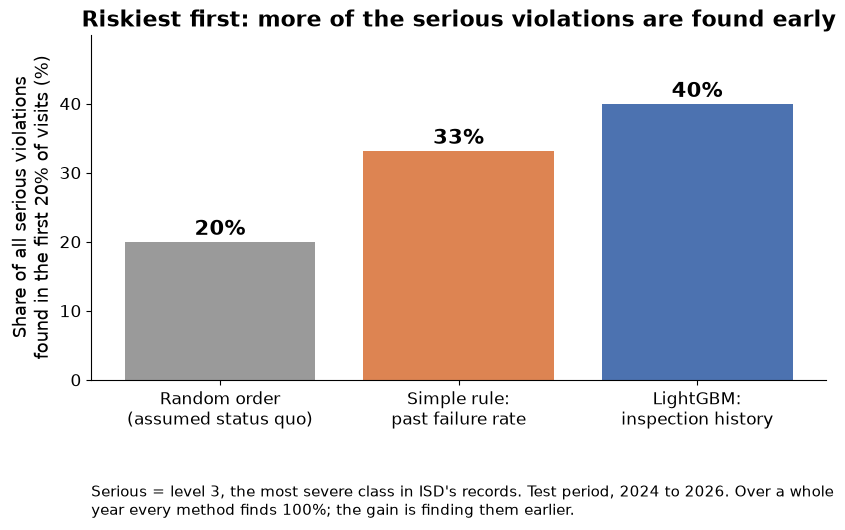

In [15]:
fig = I.plot_share_bar({name: share for name, (share, _) in severity.items()}, FINAL,
                       "Riskiest first: more of the serious violations are found early",
                       "Share of all serious violations\nfound in the first 20% of visits (%)",
                       "Serious = level 3, the most severe class in ISD's records. Test period, 2024 to 2026. Over a whole "
                       "year every method finds 100%; the gain is finding them earlier.",
                       path="../results/figures/serious_violations_bar.png")
plt.show()

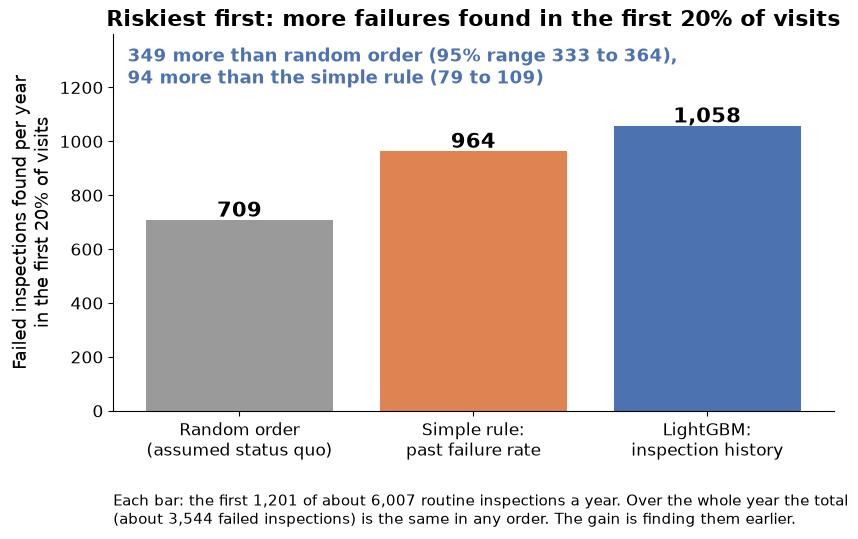

In [16]:
fig = I.plot_impact_bar(impact, FINAL, "Riskiest first: more failures found in the first 20% of visits",
                        path="../results/figures/impact_bar.png")
plt.show()

### Where the first visits go

Zip code and neighborhood are model inputs. For each neighborhood with at least 200 test inspections, the table compares its fail rate with the share of its inspections that land in the first 20% of visits under three rankings: the model, the same model with location scrambled across inspections (so only each restaurant's own record counts), and a hand rule that ignores location.

In [17]:
# For comparison: the hand rule "most violations at the last routine inspection first" does not use location.
# The same model with zip and neighborhood scrambled shows what the location input itself does.
neighborhoods = I.neighborhood_table(
    test["neighborhood"], y_test, test_scores[FINAL],
    other={"share_in_first_visits_rule_without_location": M.score_simple_rule(test)},
    other_probs={"share_in_first_visits_location_scrambled":
                 I.scrambled_first_visit_probability(final_model, test, ["zip", "neighborhood"])})
neighborhoods.to_csv("../results/neighborhood_table.csv", index=False)
neighborhoods.round(3)

,neighborhood,inspections,fail_rate,share_in_first_visits,share_in_first_visits_rule_without_location,share_in_first_visits_location_scrambled,hit_rate_in_first_visits
0,Mattapan,215,0.674,0.507,0.252,0.305,0.789
1,Hyde Park,239,0.682,0.502,0.235,0.342,0.850
2,West Roxbury,332,0.726,0.476,0.241,0.363,0.918
3,Dorchester,1643,0.664,0.458,0.240,0.350,0.851
4,Allston,690,0.699,0.438,0.318,0.301,0.930
5,Jamaica Plain,540,0.707,0.406,0.355,0.357,0.872
6,Roslindale,379,0.670,0.401,0.248,0.292,0.908
7,Mission Hill,288,0.639,0.330,0.385,0.379,0.832
8,Roxbury,1005,0.662,0.194,0.233,0.248,0.933
9,Brighton,816,0.509,0.161,0.154,0.155,0.763


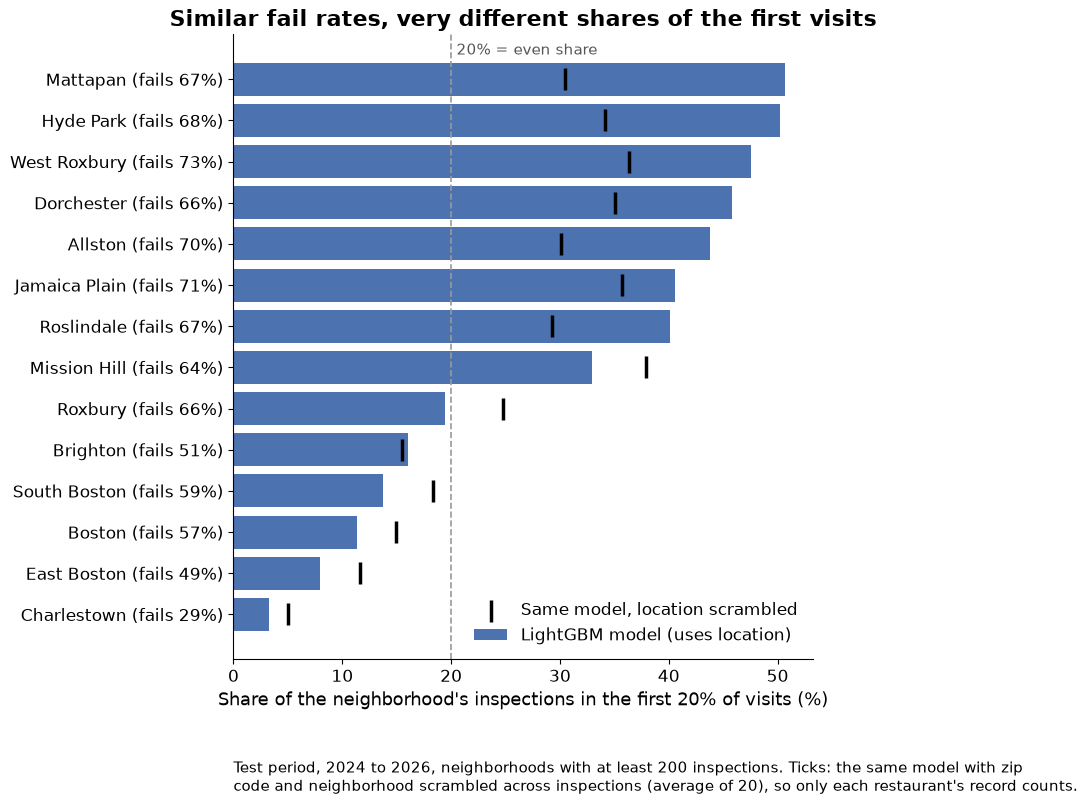

In [18]:
fig = I.plot_neighborhoods(neighborhoods, FINAL, "Similar fail rates, very different shares of the first visits",
                           path="../results/figures/neighborhood_first_visits.png")
plt.show()

Neighborhoods with similar fail rates receive very different shares of the early visits. Dorchester and Roxbury both fail 66% of the time, yet the model puts 46% of Dorchester's inspections and 19% of Roxbury's in the first 20% of visits. With location scrambled, the gap narrows to 35% and 25%: the location input causes part of it, and the restaurants' own records cause the rest. Location adds little to the hit rate (0.2 points when scrambled, see the chart above), and notebook 03 shows that the model loses half a point without it on validation, within noise. The model and the priority list below still use location, because the settings were frozen before the test. Whether to use it is a policy choice for ISD, not a technical one.

### After a pass: does a high risk score still mean something?

About one in eight of the riskiest visits ends in a pass. ISD already returns quickly to restaurants that fail. Should it also return sooner to restaurants that pass but rank as high risk? For every test inspection that passed, we look at the same restaurant's next routine inspection.

In [19]:
scored = test[["licenseno", "date", M.TARGET]].assign(score=test_scores[FINAL])
followup = I.after_a_pass(scored, table[["licenseno", "date", M.TARGET]])
followup.to_csv("../results/after_a_pass.csv", index=False)
followup.round(3)

,group,passes_with_a_later_inspection,next_inspection_fail_rate,median_days_to_next_inspection
0,"passed, ranked lower",5076,0.428,176.0
1,"passed, but ranked in the riskiest 20%",299,0.595,158.0


## 4. Priority list for the next round of inspections

The final model is refitted on all labeled data (2016 to the snapshot date). Each active restaurant then gets an estimated risk for its next inspection, as of the snapshot date. On the test years these estimates were well calibrated (see the calibration table above). "Active" means the license is active and the restaurant was inspected in the last two years. Restaurants that failed in the last 30 days are left out, because ISD re-inspects them anyway.

The three "model factors" per restaurant are the inputs that push its score up the most. They explain the model's score. They are not causes, and the score is not a finding about the business: it is a suggestion for where to look first. Location is one of the inputs, so restaurants in some neighborhoods rank higher on average. ISD should decide whether that is acceptable before using the list. The list contains business names and no owner names.

In [20]:
full = pd.read_parquet("../data/processed/inspections_full.parquet")
from src.data_pull import SNAPSHOT_END
as_of = pd.Timestamp(SNAPSHOT_END)      # the snapshot's end date, so a later re-pull gives the same list
nxt = I.next_inspection_rows(full, as_of, F.add_history_features)

# Same dtypes and categories as the training table.
nxt[M.NUM_FEATURES] = nxt[M.NUM_FEATURES].astype("float64")
for col in M.CAT_FEATURES:
    nxt[col] = pd.Categorical(nxt[col], categories=table[col].cat.categories)

if FINAL == "M2_lgbm_text":
    emb_all = T.embed_cached(table["inspection_id"], table["prior_comments"], cache_dir="../data/processed")
    pca_all = T.fit_pca(emb_all, fit_mask=has_text)
    table_all = T.add_text_features(table.drop(columns=T.TEXT_FEATURES), emb_all, pca_all)
    emb_next = T.embed_cached(nxt["inspection_id"], nxt["prior_comments"], cache_dir="../data/processed",
                              name="embeddings_next")
    nxt = T.add_text_features(nxt, emb_next, pca_all)
else:
    table_all = table

deploy_params = {k: FROZEN[FINAL][k] for k in lgbm_keys}
deploy_model = M.fit_lgbm(table_all, final_features, deploy_params)
nxt["risk"] = deploy_model.predict_proba(nxt[final_features])[:, 1]
nxt["factors"] = I.top_drivers(deploy_model, nxt[final_features], nxt, text_features=T.TEXT_FEATURES)
nxt["factors"] = nxt["factors"].replace("", "no input raises the score above average")

priority = (nxt.sort_values("risk", ascending=False)
            .assign(rank=lambda d: np.arange(1, len(d) + 1), estimated_risk_pct=lambda d: (d["risk"] * 100).round(0).astype(int))
            .assign(days_since_last_visit=lambda d: d["days_since_last"].astype(int))
            [["rank", "businessname", "licenseno", "neighborhood", "estimated_risk_pct", "days_since_last_visit", "factors"]]
            .rename(columns={"businessname": "business_name", "licenseno": "license_no", "factors": "top_3_model_factors"}))
assert not F.OWNER_COLUMNS & set(priority.columns)
priority.to_csv("../results/priority_list.csv", index=False)
open("../results/priority_list_note.md", "w").write(
    "# How to read `priority_list.csv`\n\n"
    f"The list ranks {len(priority):,} active Boston restaurants by a model's estimate of the chance that their next "
    f"routine inspection fails, as of {as_of.date()}. The estimate comes from public inspection records only.\n\n"
    "- `estimated_risk_pct` is a model estimate. It is not a finding about the business, and a high value does not "
    "mean the restaurant is unsafe today.\n"
    "- `top_3_model_factors` are the inputs that raise the estimate the most. They explain the model. They are not causes.\n"
    "- Location (zip code and neighborhood) is one of the inputs, so restaurants in some neighborhoods rank higher "
    "on average. It adds little to the ranking: scrambling it on the 2024 to 2026 inspections lowered the hit rate by "
    f"{perm.set_index('input').loc['location', 'hit_rate_drop_points']:.1f} points, and a version without it lost half "
    "a point on the 2023 validation year, within noise. We suggest ISD uses a version without location, but this list "
    "was built with location, as frozen before the test.\n"
    "- The list ranks by risk only. It does not know which restaurants are due for a visit. Use "
    "`days_since_last_visit` to combine risk with ISD's own schedule.\n"
    "- The list is a planning aid for inspectors. It is not a rating of businesses.\n"
    "- To refresh it: set `FORCE_PULL = True` in notebook 01, move `SNAPSHOT_END` in `src/data_pull.py` to today, "
    "and rerun the four notebooks.\n")
print(f"{len(priority):,} active restaurants scored as of {as_of.date()}")
priority.head(15)

priority list: 3,320 active restaurants; 157 already due a re-inspection are left out


3,163 active restaurants scored as of 2026-11-11


,rank,business_name,license_no,neighborhood,estimated_risk_pct,days_since_last_visit,top_3_model_factors
2961,1,Pho Le,68290,Dorchester,96,180,11 violations at the last routine inspection; failed 100% of past routine inspections; failed 57% of all past visits
1267,2,Fritay Restaurant,380175,Mattapan,96,83,11 violations at the last routine inspection; failed 91% of past routine inspections; failed 69% of all past visits
1677,3,BOS' Sichuan Taste,455713,Allston,96,98,8 violations at the last routine inspection; failed 87% of past routine inspections; failed 67% of all past visits
728,4,CHAU CHOW,24526,Dorchester,96,85,10 violations at the last routine inspection; failed 90% of past routine inspections; failed 52% of all past visits
1579,5,Friendship BBQ Allston,439506,Allston,95,154,"20 violations at the last routine inspection; failed 91% of past routine inspections; location (Allston, zip 02134)"
3000,6,Nhu Lan Fast Food,74834,Dorchester,95,155,7 violations at the last routine inspection; failed 98% of past routine inspections; failed 56% of all past visits
2210,7,Birdies Hot Chicken / Patty Haus,549879,Boston,95,82,12 violations at the last routine inspection; failed 100% of past routine inspections; failed 63% of all past visits
620,8,BALE RESTAURANT,22464,Dorchester,95,91,8 violations at the last routine inspection; failed 95% of past routine inspections; failed 52% of all past visits
546,9,BOURBON ST. CAFE,21201,Boston,95,86,7 violations at the last routine inspection; failed 98% of past routine inspections; failed 56% of all past visits
682,10,MCKENNA'S CAFE,23628,Dorchester,95,89,7 violations at the last routine inspection; failed 91% of past routine inspections; failed 53% of all past visits
